## 1. Install and import libraries

In [1]:
!pip -q install kagglehub tensorflow scikit-learn seaborn

In [2]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    RocCurveDisplay
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Download the dataset

In [3]:
# Download the latest version of the Kaggle dataset
path = kagglehub.dataset_download("janiobachmann/bank-marketing-dataset")
print("Path to dataset files:", path)

# Find CSV files in the downloaded folder (including subfolders)
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("CSV files found:", csv_files)

if not csv_files:
    raise FileNotFoundError("No CSV file was found in the downloaded dataset.")

# Load the first CSV file
df = pd.read_csv(csv_files[0])
print("Loaded file:", os.path.basename(csv_files[0]))

100%|██████████| 142k/142k [00:00<00:00, 39.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/janiobachmann/bank-marketing-dataset/versions/1
CSV files found: ['/root/.cache/kagglehub/datasets/janiobachmann/bank-marketing-dataset/versions/1/bank.csv']
Loaded file: bank.csv


## 3. Explore the data

In [4]:
display(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes



Dataset shape: (11162, 17)

Column names: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   

In [5]:
print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Missing values per column:


,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,11162.0,NaN,NaN,NaN,41.231948,11.913369,18.0,32.0,39.0,49.0,95.0
job,11162,12,management,2566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,11162,3,married,6351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,11162,4,secondary,5476,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,11162,2,no,10994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,11162.0,NaN,NaN,NaN,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.0,81204.0
housing,11162,2,no,5881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,11162,2,no,9702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,11162,3,cellular,8042,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,11162.0,NaN,NaN,NaN,15.658036,8.42074,1.0,8.0,15.0,22.0,31.0


In [6]:
# Identify the target column across common Bank Marketing dataset versions
possible_targets = ["deposit", "y", "subscribed", "term_deposit"]
target_candidates = [col for col in df.columns if col.lower() in possible_targets]

if not target_candidates:
    raise ValueError(
        "Could not identify the target column. Expected one of: "
        "'deposit', 'y', 'subscribed', or 'term_deposit'. "
        f"Available columns: {df.columns.tolist()}"
    )

TARGET = target_candidates[0]
print("Target column:", TARGET)
print("\nTarget distribution:")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))
print("\nTarget percentages:")
display((df[TARGET].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percentage"))

Target column: deposit

Target distribution:


,count
deposit,
no,5873
yes,5289



Target percentages:


,percentage
deposit,
no,52.62
yes,47.38


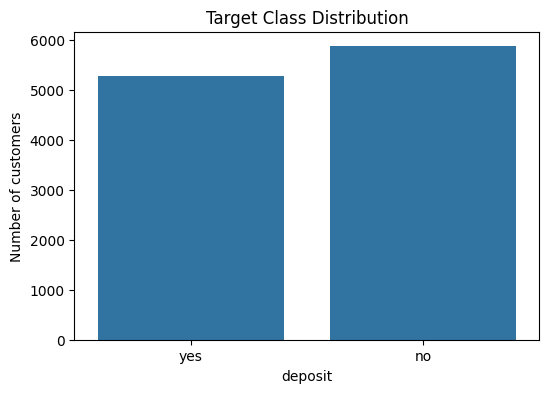

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Target Class Distribution")
plt.xlabel(TARGET)
plt.ylabel("Number of customers")
plt.show()

## 4. Prepare the target and features

The target is converted to binary values:
- `1` = customer subscribes
- `0` = customer does not subscribe

For this dataset, positive values are usually `yes` and negative values are `no`. The mapping below also supports numeric and boolean target values.


In [8]:
data = df.copy()

# Remove rows where the target is missing
data = data.dropna(subset=[TARGET]).copy()

# Normalize target labels and map them to 0/1
target_values = data[TARGET].astype(str).str.strip().str.lower()
unique_values = set(target_values.unique())

if unique_values.issubset({"yes", "no"}):
    y = target_values.map({"no": 0, "yes": 1}).astype(int)
elif unique_values.issubset({"true", "false"}):
    y = target_values.map({"false": 0, "true": 1}).astype(int)
elif unique_values.issubset({"0", "1"}):
    y = target_values.astype(int)
else:
    # Fallback for an unexpected two-class target
    if len(unique_values) != 2:
        raise ValueError(f"Expected a binary target, but found: {unique_values}")
    mapping = {value: idx for idx, value in enumerate(sorted(unique_values))}
    print("Applying target mapping:", mapping)
    y = target_values.map(mapping).astype(int)

X = data.drop(columns=[TARGET])

# Remove fully duplicated feature rows only if present; retain target alignment
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target mapping: 0 = no / negative class, 1 = yes / positive class (where applicable)")

Features shape: (11162, 16)
Target shape: (11162,)
Target mapping: 0 = no / negative class, 1 = yes / positive class (where applicable)


## 5. Train-test split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training features: (8929, 16)
Testing features: (2233, 16)

Training target distribution:
deposit
0    0.526151
1    0.473849
Name: proportion, dtype: float64

Testing target distribution:
deposit
0    0.526198
1    0.473802
Name: proportion, dtype: float64


## 6. Preprocess numerical and categorical features

- Numerical columns: missing values are filled using the median, then values are standardized.
- Categorical columns: missing values are filled using the most frequent value, then one-hot encoded.
- The preprocessing pipeline is fitted on the training data only to avoid data leakage.


In [10]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert to float32 for TensorFlow
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Numerical features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Processed training shape: (8929, 51)
Processed testing shape: (2233, 51)


## 7. Build the Artificial Neural Network (ANN)

In [11]:
input_dim = X_train_processed.shape[1]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(input_dim,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Train the ANN

Early stopping monitors validation loss and restores the best model weights to help reduce overfitting.


In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
224/224 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.7281 - auc: 0.8039 - loss: 0.5403 - precision: 0.7262 - recall: 0.6764 - val_accuracy: 0.8163 - val_auc: 0.8919 - val_loss: 0.4222 - val_precision: 0.8339 - val_recall: 0.7806
Epoch 2/100
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8151 - auc: 0.8869 - loss: 0.4250 - precision: 0.7985 - recall: 0.8111 - val_accuracy: 0.8275 - val_auc: 0.8995 - val_loss: 0.4035 - val_precision: 0.8371 - val_recall: 0.8046
Epoch 3/100
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8233 - auc: 0.8990 - loss: 0.4001 - precision: 0.7985 - recall: 0.8346 - val_accuracy: 0.8365 - val_auc: 0.9029 - val_loss: 0.3911 - val_precision: 0.8347 - val_recall: 0.8309
Epoch 4/100
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8334 - auc: 0.9024 - loss: 0.3907 - precision: 0.8034 - recall: 0.8546 - val_accuracy: 0.8427 - val_auc: 0.9046 - val_loss: 0.3859 - val_precision: 0.8271 - val_recall: 0.8583
Epoch 5/100
224/224 ━━━━━━━

## 9. Visualize the training process

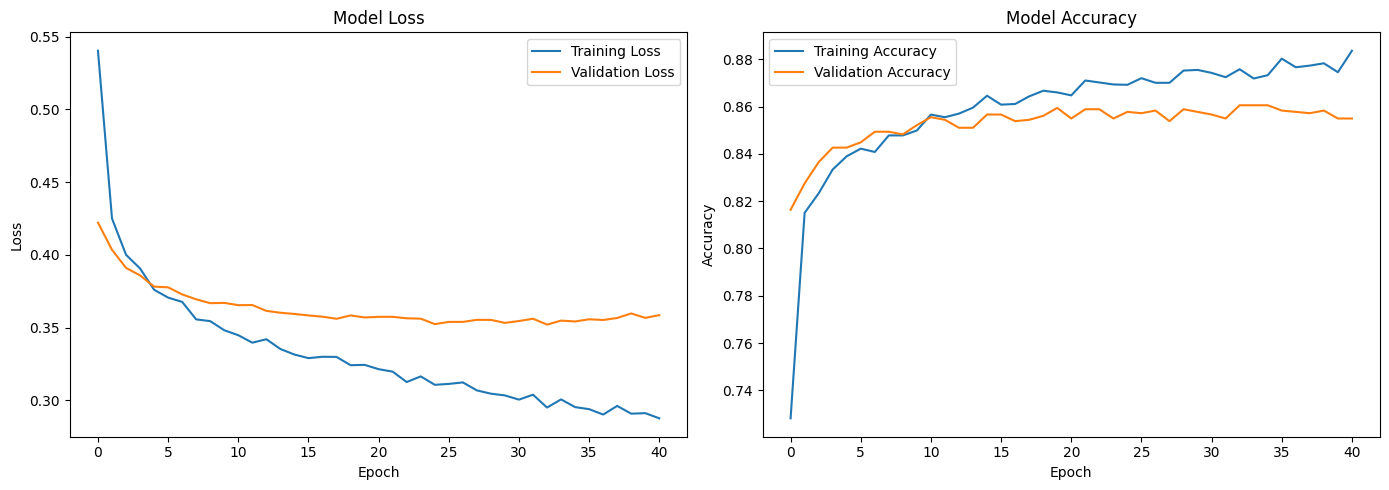

In [13]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Evaluate the model on the test set

In [14]:
# Predict probabilities and convert them to class labels using a 0.50 threshold
y_prob = model.predict(X_test_processed).ravel()
y_pred = (y_prob >= 0.50).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, auc]
})

display(results.style.format({"Score": "{:.4f}"}))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Metric,Score
0,Accuracy,0.8616
1,Precision,0.8265
2,Recall,0.8960
3,F1-score,0.8599
4,ROC-AUC,0.9217



Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.83      0.86      1175
           1       0.83      0.90      0.86      1058

    accuracy                           0.86      2233
   macro avg       0.86      0.86      0.86      2233
weighted avg       0.86      0.86      0.86      2233



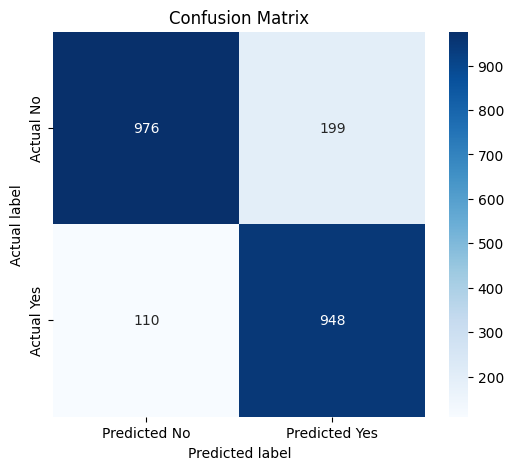

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()

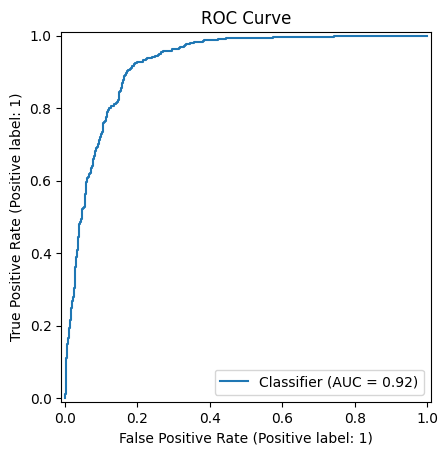

In [16]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve")
plt.show()

## 11. Optional: Experiment with the classification threshold

The default threshold is 0.50. In a marketing campaign, the preferred threshold may depend on the relative cost of contacting customers versus missing likely subscribers. Compare precision and recall at different thresholds.


In [17]:
threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    pred_at_threshold = (y_prob >= threshold).astype(int)
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred_at_threshold),
        "Precision": precision_score(y_test, pred_at_threshold, zero_division=0),
        "Recall": recall_score(y_test, pred_at_threshold, zero_division=0),
        "F1-score": f1_score(y_test, pred_at_threshold, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.8468,0.7814,0.9395,0.8532
1,0.4,0.8598,0.8076,0.9244,0.8621
2,0.5,0.8616,0.8265,0.8960,0.8599
3,0.6,0.8495,0.8324,0.8544,0.8433
4,0.7,0.8383,0.8574,0.7902,0.8224


## 12. Conclusion

The Artificial Neural Network (ANN) model successfully predicted whether a bank customer would subscribe to a term deposit. The model achieved 86.16% accuracy, with a precision of 82.65%, recall of 89.60%, F1-score of 85.99%, and an ROC-AUC of 92.17%. These results indicate that the model has a strong ability to distinguish between customers who subscribe and those who do not.

The model achieved higher recall than precision, meaning it was more effective at identifying potential subscribers, although it also produced some false positive predictions. The training and validation results were relatively close, suggesting reasonable generalization with a limited degree of overfitting.

The threshold comparison showed that 0.40 achieved the highest F1-score of 86.21% and a recall of 92.44%, while the default threshold of 0.50 achieved the highest accuracy of 86.16%. Therefore, the best threshold depends on the bank's objective: identifying as many potential subscribers as possible or maintaining overall prediction accuracy.

Overall, the ANN demonstrated strong performance on the Bank Marketing Dataset and can support banks in identifying customers who are more likely to subscribe to term deposits. However, further improvements could be explored by testing different ANN architectures, comparing the model with other machine learning algorithms, and evaluating its performance without the duration feature, since call duration may not be available before contacting a customer.
